# V3: internal-layout similarity

We want useful architectural precedents based on **room programme and spatial arrangement**. V2 learns to redraw 128 px images; its 86% shifted-copy result measures recognition of the same drawing, not relevance between different homes.

This notebook builds an interpretable structural baseline before we train a new encoder. It includes annotation inspection, room/wall/door masks, rotation-aware search and a human-review benchmark. **No new model has been trained or improvement demonstrated yet.**

Run the synthetic checks without data. For real retrieval, extract the original annotated CubiCasa5K dataset locally and set `DATASET_ROOT`. The existing image-only NPZ is insufficient. Install the project requirements in your notebook environment. Generated artifacts go under the ignored data directory; the original notebook and server remain unchanged.


In [18]:
from pathlib import Path
from collections import Counter
import json, re, hashlib, tempfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from matplotlib.colors import ListedColormap
from IPython.display import display

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / '01_autoencoder' / 'notebook').is_dir()), None)
if PROJECT is None:
    raise RuntimeError('Open Jupyter from inside this project.')
DATASET_ROOT = Path(
    r"C:\Users\Chloe\hackathon-team6-cubicasa-main\01_autoencoder\data\cubicasa5k"
)
OUTPUT = PROJECT / '01_autoencoder/data/internal_layout_v3'
OUTPUT.mkdir(parents=True, exist_ok=True)
SIZE, SEED = 256, 42
RUN_COLLECTION = True  # Enable after inspecting annotation overlays.
MAX_PLANS = None       # e.g. 100 for debugging; None for the full collection.
TYPES = ('Bedroom','Bath','Sauna','Kitchen','LivingRoom','Dining','Circulation','Storage','Garage','Other')
TYPE_ID = {name:i+1 for i,name in enumerate(TYPES)}
ALIASES = {'HallWay':'Circulation','Hall':'Circulation','Entry':'Circulation',
           'DraughtLobby':'Circulation','Closet':'Storage','DressingRoom':'Storage',
           'Pantry':'Storage','CarPort':'Garage','Lounge':'LivingRoom','EatingArea':'Dining'}
COLOURS = ['white','#4477aa','#66ccee','#228833','#ccbb44','#ee6677',
           '#aa3377','#bbbbbb','#ddaa33','#009988','#9999cc']
WEIGHTS = {'counts':.30,'areas':.20,'positions':.40,'shape':.10}
FLOORS = {'counts':1.,'areas':.02,'positions':.01,'shape':.10}
print('Dataset:', DATASET_ROOT, '| exists:', DATASET_ROOT.exists())


Dataset: C:\Users\Chloe\hackathon-team6-cubicasa-main\01_autoencoder\data\cubicasa5k | exists: True


## 1. Define a useful match

Initial ranking weights are **30% room counts, 20% area proportions, 40% spatial arrangement, 10% footprint proportions**. These are hypotheses: tune on validation queries, then freeze before reviewing test queries.

Bathroom and sauna stay separate. Counts describe annotation instances, which may differ from an architect's room programme for open-plan homes. Unknown room types become `Other`; original labels remain available for audit. Outdoor rooms are excluded. Areas are relative, not square metres.

Search tests four right-angle rotations of each complete plan. Reflections are not included. **Door connectivity is not scored yet:** nearby rooms do not necessarily connect, and a door mask alone does not establish the room pair. We must visually validate that extraction before relying on it.


## 2. Read SVG annotations and preserve geometry

The [official CubiCasa loader](https://github.com/CubiCasa/CubiCasa5k/blob/master/floortrans/loaders/house.py) identifies `Space` groups and `Wall`, `Door`, `Window` IDs. Its [dataset loader](https://github.com/CubiCasa/CubiCasa5k/blob/master/floortrans/loaders/svg_loader.py) pairs `model.svg` with `F1_scaled.png`.

This restricted reader takes the first polygon of each semantic group and supports inherited SVG affine transforms. Unsupported geometry fails visibly rather than generating an empty plan. It is not a general SVG renderer. Verify the coordinate alignment on real drawings before building features.

We crop using internal rooms plus structure, preserve aspect ratio, and draw categorical polygons directly at 256 px. The saved transform maps original coordinates into the square. Footprint here means room regions plus walls, not a reconstructed exterior boundary.


In [19]:
NUMBER = r'[-+]?(?:\d*\.\d+|\d+\.?\d*)(?:[eE][-+]?\d+)?'
def transform(text):
    matrix = np.eye(3)
    if re.sub(r'[A-Za-z]+\s*\([^)]*\)', '', text).strip(' ,\t\n'):
        raise ValueError(f'Unsupported transform: {text}')
    for name,args in re.findall(r'([A-Za-z]+)\s*\(([^)]*)\)',text):
        a = [float(v) for v in re.findall(NUMBER,args)]; t = np.eye(3)
        if name == 'matrix' and len(a)==6:
            t = np.array([[a[0],a[2],a[4]],[a[1],a[3],a[5]],[0,0,1.]])
        elif name == 'translate' and len(a) in (1,2):
            t[:2,2] = [a[0],a[1] if len(a)==2 else 0]
        elif name == 'scale' and len(a) in (1,2):
            t[0,0],t[1,1] = a[0],a[-1]
        elif name == 'rotate' and len(a) in (1,3):
            c,s = np.cos(np.deg2rad(a[0])),np.sin(np.deg2rad(a[0]))
            t[:2,:2] = [[c,-s],[s,c]]
            if len(a)==3:
                center=np.array(a[1:]); t[:2,2]=center-t[:2,:2]@center
        elif name in ('skewX','skewY') and len(a)==1:
            t[0 if name=='skewX' else 1,1 if name=='skewX' else 0]=np.tan(np.deg2rad(a[0]))
        else:
            raise ValueError(f'Unsupported transform: {name}({args})')
        matrix = matrix @ t
    return matrix

def read_svg(path):
    root=ET.parse(path).getroot(); found={}; expected={}
    def walk(element,parent,semantic=None,token=None):
        matrix=parent@transform(element.get('transform',''))
        classes=element.get('class','').split(); ident=element.get('id','')
        if 'Space' in classes:
            position=classes.index('Space')
            if position+1>=len(classes): raise ValueError('Space without a type')
            semantic=('room',classes[position+1]); token=id(element); expected[token]=semantic
        elif ident in ('Wall','Door','Window'):
            semantic=(ident.lower(),ident); token=id(element); expected[token]=semantic
        if element.tag.split('}')[-1]=='polygon' and semantic and token not in found:
            values=[float(v) for v in re.findall(NUMBER,element.get('points',''))]
            if len(values)<6 or len(values)%2: raise ValueError('Invalid polygon')
            xy=np.array(values).reshape(-1,2)
            xy=(np.column_stack([xy,np.ones(len(xy))])@matrix.T)[:,:2]
            if not np.isfinite(xy).all(): raise ValueError('Non-finite coordinates')
            raw=semantic[1]
            found[token]={'kind':semantic[0],'raw_type':raw,'points':xy,
                          'type':ALIASES.get(raw,raw if raw in TYPE_ID else 'Other')}
        for child in element: walk(child,matrix,semantic,token)
    walk(root,np.eye(3))
    if set(expected)-set(found): raise ValueError('Semantic group without supported polygon')
    records=list(found.values())
    if not any(r['kind']=='room' and r['raw_type']!='Outdoor' for r in records):
        raise ValueError('No internal room polygons')
    return records

def rasterize(records):
    rooms=[r for r in records if r['kind']=='room' and r['raw_type']!='Outdoor']
    structure=[r for r in records if r['kind'] in ('wall','door','window')]
    xy=np.concatenate([r['points'] for r in rooms+structure])
    lo,hi=xy.min(axis=0),xy.max(axis=0); side=float((hi-lo).max())
    if side<=0: raise ValueError('Degenerate bounds')
    scale=(SIZE-5)/side; offset=(SIZE-(hi-lo)*scale)/2-lo*scale
    def polygon(r): return [tuple(p) for p in r['points']*scale+offset]
    instance=Image.new('I',(SIZE,SIZE),0); semantic=Image.new('L',(SIZE,SIZE),0)
    for i,room in enumerate(rooms,1):
        ImageDraw.Draw(instance).polygon(polygon(room),fill=i)
        ImageDraw.Draw(semantic).polygon(polygon(room),fill=TYPE_ID[room['type']])
    masks={'instance':np.asarray(instance,dtype=np.int32),'semantic':np.asarray(semantic,dtype=np.uint8)}
    for kind in ('wall','door','window'):
        image=Image.new('L',(SIZE,SIZE),0)
        for r in structure:
            if r['kind']==kind: ImageDraw.Draw(image).polygon(polygon(r),fill=1)
        masks[kind]=np.asarray(image,dtype=np.uint8)
    if any(not (masks['instance']==i).any() for i in range(1,len(rooms)+1)):
        raise ValueError('A room vanished or was overwritten at this resolution')
    masks['footprint']=((masks['instance']>0)|(masks['wall']>0)).astype(np.uint8)
    return {'rooms':rooms,'masks':masks,'transform':{'scale':scale,'offset':offset.tolist(),
            'bounds':[lo.tolist(),hi.tolist()],'size':SIZE}}

def load_plan(folder):
    layout=rasterize(read_svg(Path(folder)/'model.svg')); layout['folder']=str(folder)
    return layout


## 3. Inspect drawings and masks

Look for room boundaries displaced from the original drawing, missing spaces, tiny rooms, unexpected `Other` labels and lost doors. Stop and fix alignment problems before trusting search. Thin details can still disappear at 256 px.

The original drawing below stays in its original coordinate frame; the categorical map is cropped and padded. The colour legend distinguishes categories, not room instances. Red/green/blue in the last panel indicate walls/doors/windows.


Annotated plans: 5000


,type,colour
0,Bedroom,#4477aa
1,Bath,#66ccee
2,Sauna,#228833
3,Kitchen,#ccbb44
4,LivingRoom,#ee6677
5,Dining,#aa3377
6,Circulation,#bbbbbb
7,Storage,#ddaa33
8,Garage,#009988
9,Other,#9999cc


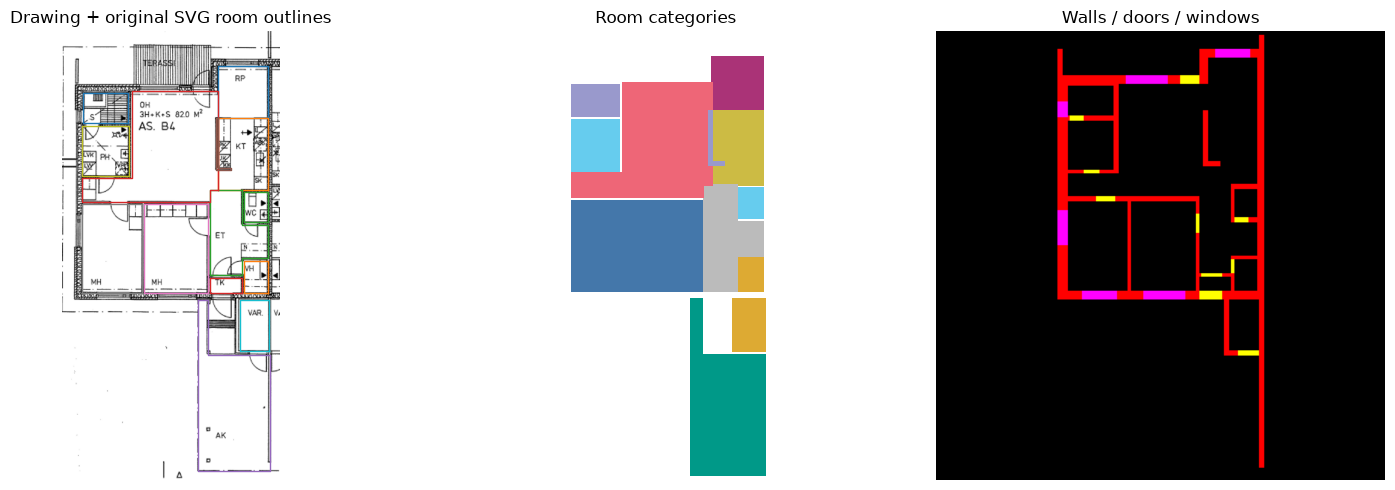

Dining          1
Kitchen         1
Entry           1
LivingRoom      1
CarPort         1
Undefined       2
Bedroom         2
Bath            2
Storage         1
Closet          1
DraughtLobby    1
Name: annotation count, dtype: int64

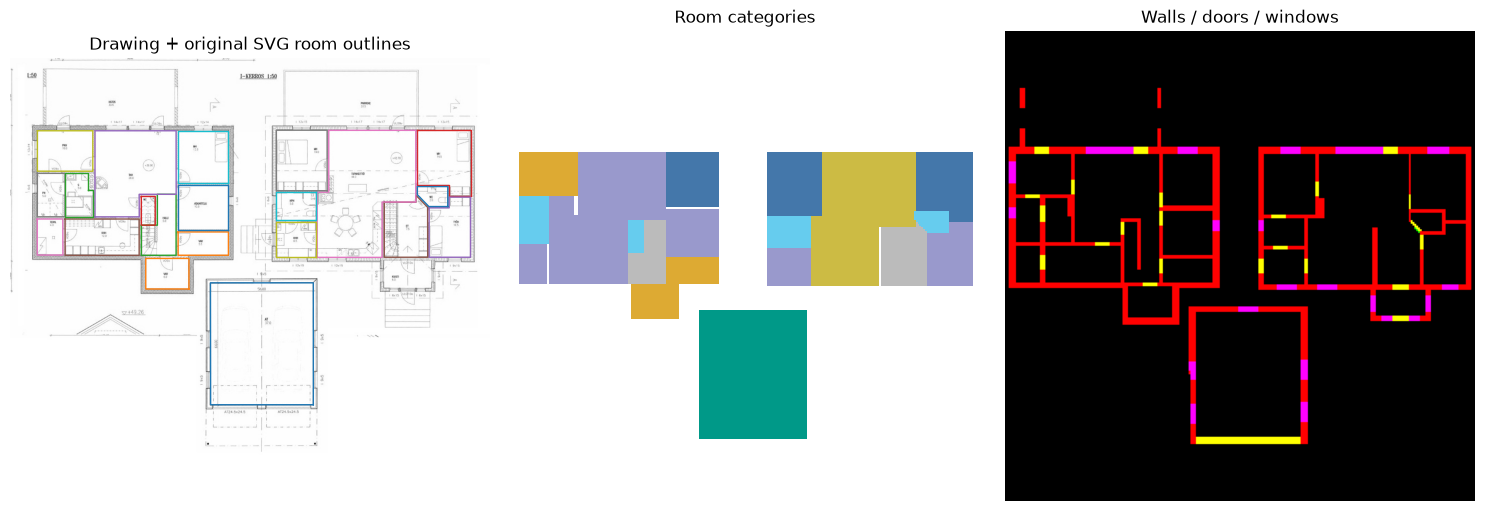

Garage            1
Storage           2
Hall              1
Bath              4
Den               1
Utility           2
TechnicalRoom     1
DressingRoom      1
Bedroom           3
RecreationRoom    1
Undefined         1
Office            1
Entry             1
Kitchen           1
Name: annotation count, dtype: int64

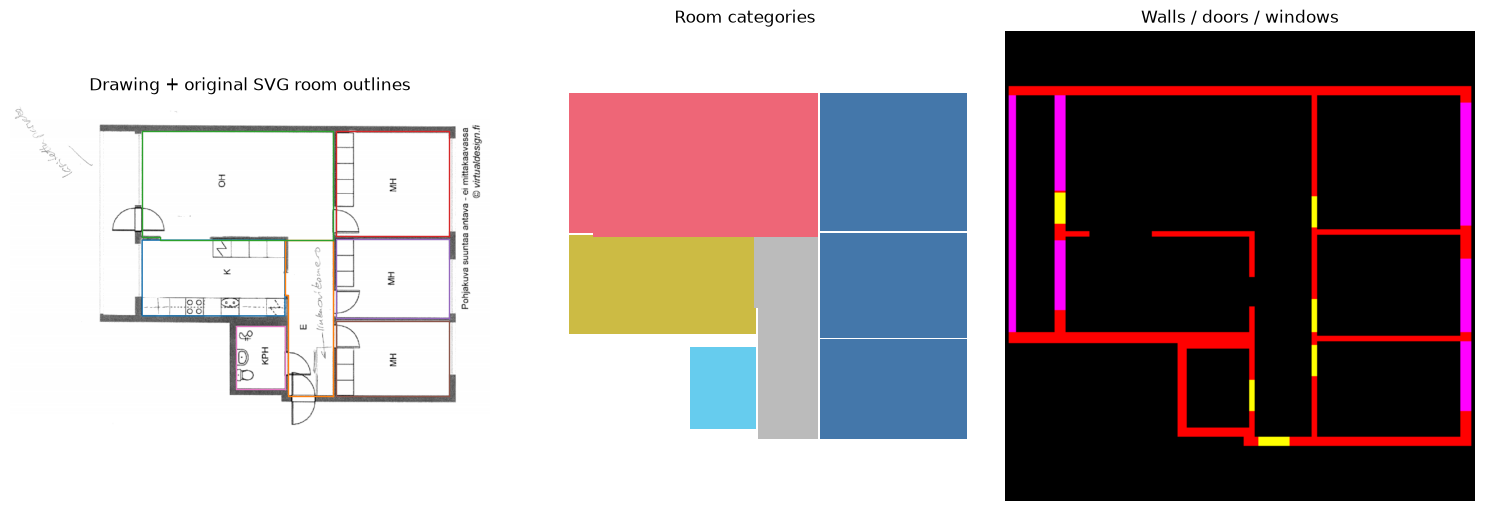

Kitchen       1
Entry         1
LivingRoom    1
Bedroom       3
Bath          1
Name: annotation count, dtype: int64

In [20]:
def inspect(layout):
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    if 'folder' in layout:
        with Image.open(Path(layout['folder'])/'F1_scaled.png') as image: axes[0].imshow(image.copy())
        for room in layout['rooms']:
            p=np.vstack([room['points'],room['points'][0]])
            axes[0].plot(p[:,0],p[:,1],linewidth=1)
    else: axes[0].text(.1,.5,'Synthetic example: no source drawing')
    axes[0].set_title('Drawing + original SVG room outlines')
    axes[1].imshow(layout['masks']['semantic'],cmap=ListedColormap(COLOURS),vmin=0,vmax=len(TYPES),interpolation='nearest')
    axes[1].set_title('Room categories')
    axes[2].imshow(np.stack([layout['masks'][k] for k in ('wall','door','window')],axis=-1).astype(float))
    axes[2].set_title('Walls / doors / windows')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()
    display(pd.Series(Counter(r['raw_type'] for r in layout['rooms']),name='annotation count'))

available=sorted(DATASET_ROOT.rglob('model.svg')) if DATASET_ROOT.exists() else []
print('Annotated plans:',len(available))
display(pd.DataFrame({'type':TYPES,'colour':COLOURS[1:]}))
if available:
    picks=np.random.default_rng(SEED).choice(len(available),min(20,len(available)),replace=False)
    for i in picks[:3]: inspect(load_plan(available[i].parent))  # Inspect all 20 before a full run.
else: print('Extract annotated data and set DATASET_ROOT. Synthetic checks below still run.')


## 4. Features and ranking

For each category we calculate its room count and fraction of internal room area. A **4 by 4 grid per category** describes its spatial distribution. Shape is log footprint width/height. These summaries are intentionally coarse: identical counts and similar grid occupancy do not guarantee equivalent circulation.

Standardisation uses training plans only, including their four orientations. Scale floors prevent nearly constant features from dominating. Each block contributes its mean absolute standardised difference, so the many grid features do not win merely because there are more of them. The winning rotation minimises the complete weighted score. Distances are ranking scores, not probabilities.


In [21]:
def features(layout,rotation=0):
    semantic=np.rot90(layout['masks']['semantic'],rotation)
    instance=np.rot90(layout['masks']['instance'],rotation)
    footprint=np.rot90(layout['masks']['footprint'],rotation)
    total=max(1,int((instance>0).sum()))
    counts=np.array([sum(r['type']==name for r in layout['rooms']) for name in TYPES],dtype=float)
    areas=np.array([(semantic==TYPE_ID[name]).sum()/total for name in TYPES])
    positions=[]
    for name in TYPES:
        for ys in np.array_split(np.arange(SIZE),4):
            for xs in np.array_split(np.arange(SIZE),4):
                positions.append((semantic[np.ix_(ys,xs)]==TYPE_ID[name]).sum()/total)
    y,x=np.where(footprint)
    return {'counts':counts,'areas':areas,'positions':np.array(positions),
            'shape':np.array([np.log((np.ptp(x)+1)/(np.ptp(y)+1))])}

class StructuralIndex:
    def __init__(self,feature_rows,splits):
        if len(feature_rows)!=len(splits): raise ValueError('Features and splits must align')
        train=np.asarray(splits)=='train'
        if not train.any(): raise ValueError('Need training plans to fit scales')
        self.values={}; self.center={}; self.scale={}; self.weights=dict(WEIGHTS)
        for block in self.weights:
            raw=np.array([[v[r][block] for r in range(4)] for v in feature_rows])
            training=raw[train].reshape(-1,raw.shape[-1])
            self.center[block]=training.mean(axis=0)
            self.scale[block]=np.maximum(training.std(axis=0),FLOORS[block])
            self.values[block]=(raw-self.center[block])/self.scale[block]
    def search(self,query,candidates=None,exclude=None,k=5):
        candidates=np.arange(len(self.values['counts'])) if candidates is None else np.asarray(candidates,dtype=int)
        if exclude is not None: candidates=candidates[candidates!=exclude]
        if not len(candidates): raise ValueError('No gallery candidates')
        q=features(query)
        parts={b:np.abs(self.values[b][candidates]-(q[b]-self.center[b])/self.scale[b]).mean(axis=-1) for b in self.weights}
        scores=sum(self.weights[b]*parts[b] for b in self.weights)
        rotations=scores.argmin(axis=1); rows=np.arange(len(candidates)); best=scores[rows,rotations]
        order=np.argsort(best,kind='stable')[:k]
        return pd.DataFrame([{'index':int(candidates[i]),'distance':float(best[i]),
            'rotation':int(rotations[i]*90),**{f'distance_{b}':float(parts[b][i,rotations[i]]) for b in self.weights}} for i in order])


## 5. Synthetic checks without the dataset

These invented rectangle layouts check identity, rotation, different arrangements and self-exclusion. A temporary SVG checks inherited transforms and room aliases. Passing these checks validates mechanics only; it provides no evidence of useful real-world matches.


Synthetic checks passed; not a retrieval-quality result.


,distance,rotation,distance_counts,distance_areas,distance_positions,distance_shape
index,,,,,,
0,0.000000,0,0.0,0.000000,0.00000,0.0
2,0.000000,270,0.0,0.000000,0.00000,0.0
1,0.206645,180,0.0,0.424264,0.30448,0.0


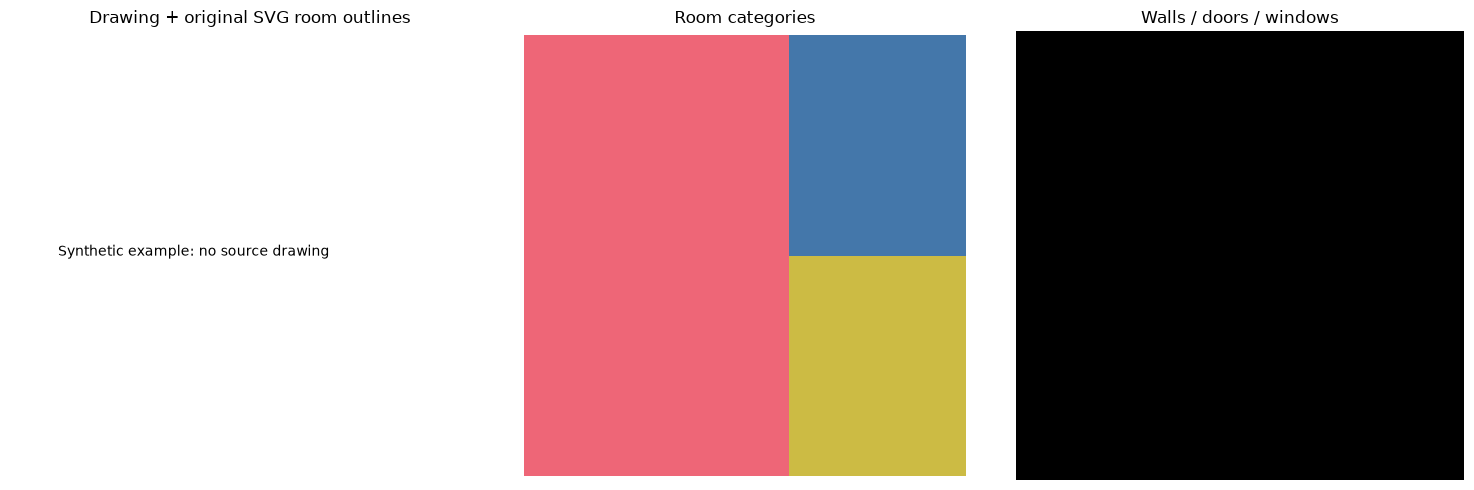

LivingRoom    1
Bedroom       1
Kitchen       1
Name: annotation count, dtype: int64

In [22]:
def synthetic(swapped=False):
    names=['LivingRoom','Bedroom','Kitchen'] if not swapped else ['Bedroom','LivingRoom','Kitchen']
    boxes=[(0,0,60,100),(60,0,100,50),(60,50,100,100)]
    records=[]
    for name,(x0,y0,x1,y1) in zip(names,boxes):
        records.append({'kind':'room','raw_type':name,'type':name,
            'points':np.array([[x0,y0],[x1,y0],[x1,y1],[x0,y1]],dtype=float)})
    return rasterize(records)
a,b=synthetic(),synthetic(True)
c=dict(a,masks={k:np.rot90(v) for k,v in a['masks'].items()})
demo_index=StructuralIndex([[features(p,r) for r in range(4)] for p in (a,b,c)],['train']*3)
demo=demo_index.search(a,k=3).set_index('index')
assert np.isclose(demo.loc[0,'distance'],0) and np.isclose(demo.loc[2,'distance'],0)
assert demo.loc[1,'distance']>0
assert 0 not in demo_index.search(a,exclude=0)['index'].tolist()
with tempfile.TemporaryDirectory() as directory:
    path=Path(directory)/'model.svg'
    path.write_text('<svg><g transform="translate(10 20)"><g class="Space HallWay">'
                    '<polygon points="0,0 20,0 20,20 0,20"/></g></g></svg>',encoding='utf-8')
    parsed=read_svg(path)
    assert parsed[0]['type']=='Circulation'
    np.testing.assert_allclose(parsed[0]['points'][0],[10,20])
print('Synthetic checks passed; not a retrieval-quality result.')
display(demo); inspect(a)


## 6. Build the collection with official splits

Set `RUN_COLLECTION=True` after inspecting real annotations. The dataset must include one each of `train.txt`, `val.txt` and `test.txt`. We preserve their membership and fail on missing or ambiguous matches. Parsing/rasterisation failures go to a CSV for review. Never substitute empty masks for failed plans.

Only compact features remain in memory; masks load on demand. The manifest retains source annotation hashes. A subset run is for debugging and is not comparable to a full benchmark. Generated artifacts include the manifest, feature arrays, fitted scales, configuration and failures.


In [ ]:
def canonical(text):
    parts=text.strip().replace('\\','/').strip('/').split('/')
    if parts[-1] in ('model.svg','F1_scaled.png','F1_original.png'): parts=parts[:-1]
    return '/'.join(parts)

def official_splits():
    lookup={}
    for split in ('train','val','test'):
        files=list(DATASET_ROOT.rglob(f'{split}.txt'))
        if len(files)!=1: raise ValueError(f'Expected one {split}.txt, found {len(files)}')
        for line in files[0].read_text(encoding='utf-8-sig').splitlines():
            if not line.strip(): continue
            key=canonical(line)
            if key in lookup: raise ValueError(f'Duplicate split entry: {key}')
            lookup[key]=split
    return lookup

index=None; manifest=pd.DataFrame()
if RUN_COLLECTION:
    if not available: raise FileNotFoundError(f'No annotated plans under {DATASET_ROOT}')
    lookup=official_splits(); feature_rows=[]; rows=[]; failures=[]
    for svg in available[:MAX_PLANS]:
        relative=svg.parent.relative_to(DATASET_ROOT).as_posix()
        keys=[key for key in lookup if relative==key or relative.endswith('/'+key)]
        if len(keys)!=1: raise ValueError(f'No unique split for {relative}: {keys}')
        try:
            if not (svg.parent/'F1_scaled.png').exists(): raise ValueError('Missing scaled drawing')
            layout=load_plan(svg.parent)
            feature_rows.append([features(layout,r) for r in range(4)])
            rows.append({'id':keys[0],'folder':str(svg.parent),'split':lookup[keys[0]],
                'rooms':len(layout['rooms']),'svg_sha256':hashlib.sha256(svg.read_bytes()).hexdigest()})
        except (ValueError,OSError,ET.ParseError) as error:
            failures.append({'id':relative,'error':str(error)})
        if (len(rows)+len(failures))%250==0: print('Processed:',len(rows)+len(failures))
    pd.DataFrame(failures,columns=['id','error']).to_csv(OUTPUT/'annotation_failures.csv',index=False)
    if not rows: raise RuntimeError('No valid plans. Inspect annotation_failures.csv')
    manifest=pd.DataFrame(rows); index=StructuralIndex(feature_rows,manifest['split'])
    manifest.to_csv(OUTPUT/'manifest.csv',index=False)
    np.savez_compressed(OUTPUT/'features.npz',**{f'values_{b}':index.values[b] for b in WEIGHTS},
        **{f'center_{b}':index.center[b] for b in WEIGHTS},**{f'scale_{b}':index.scale[b] for b in WEIGHTS})
    config={'version':'v3-structural-baseline-1','size':SIZE,'types':TYPES,'aliases':ALIASES,
        'weights':WEIGHTS,'floors':FLOORS,'rotations':[0,90,180,270],'grid':4,'seed':SEED,
        'partial_collection':MAX_PLANS is not None,'connectivity':False,
        'distance':'weighted block mean absolute standardized difference'}
    (OUTPUT/'config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
    display(manifest.groupby('split').agg(plans=('id','size'),median_rooms=('rooms','median')))
    print('Valid:',len(rows),'| failures:',len(failures),'; review failures before interpreting results.')
else: print('Collection disabled. Inspect samples, then set RUN_COLLECTION=True.')


Processed: 250
Processed: 500
Processed: 750
Processed: 1000
Processed: 1250
Processed: 1500
Processed: 1750
Processed: 2000
Processed: 2250
Processed: 2500
Processed: 2750
Processed: 3000
Processed: 3250
Processed: 3500
Processed: 3750
Processed: 4000


## 7. Search different plans

Validation and test queries search the **training gallery**. Exclude the query itself. During development use validation queries; reserve test queries until settings are frozen. Distance components explain whether programme or arrangement drives a match. The maps below are rotated into the best complete-plan alignment; original drawings keep their original orientation.


In [ ]:
def retrieve(qi,k=5):
    query=load_plan(manifest.iloc[qi]['folder'])
    gallery=np.flatnonzero(manifest['split'].eq('train').to_numpy())
    matches=index.search(query,gallery,exclude=qi,k=k)
    matches['id']=manifest.iloc[matches['index']]['id'].to_numpy()
    return query,matches

def show_plans(ids,rotations=None):
    rotations=[0]*len(ids) if rotations is None else rotations
    by_id=manifest.set_index('id'); fig,axes=plt.subplots(2,len(ids),figsize=(3*len(ids),6),squeeze=False)
    for col,(pid,rotation) in enumerate(zip(ids,rotations)):
        layout=load_plan(by_id.loc[pid,'folder'])
        with Image.open(Path(layout['folder'])/'F1_scaled.png') as image: axes[0,col].imshow(image.copy())
        axes[0,col].set_title(pid,fontsize=8)
        axes[1,col].imshow(np.rot90(layout['masks']['semantic'],rotation//90),
            cmap=ListedColormap(COLOURS),vmin=0,vmax=len(TYPES),interpolation='nearest')
        axes[1,col].set_title(f'Alignment: {rotation} degrees')
    for ax in axes.flat: ax.axis('off')
    plt.tight_layout(); plt.show()

if index is not None:
    validation=np.flatnonzero(manifest['split'].eq('val').to_numpy())
    if len(validation):
        qi=int(validation[0]); query,matches=retrieve(qi)
        show_plans([manifest.iloc[qi]['id']]+matches['id'].tolist(),[0]+matches['rotation'].tolist())
        display(matches)


## 8. Create a human review benchmark

Start with up to **30 validation queries**, sampled reproducibly across room-count bands. Inspect their typological diversity and document any manual changes before tuning weights. Candidates pool structural top five, five random training plans and optional v2 top five.

For a fair v2 comparison, export `v2_rankings.csv` under `OUTPUT`, with columns `query_id,candidate_id,rank`. V2 must use exactly the selected queries and the same training gallery. No automatic v2 inference runs here; its weights are not stored locally in this repository.

The review CSV hides retrieval methods/ranks and shuffles pairs. Label **2 = strong match, 1 = partial match, 0 = poor match**. Consider room programme, arrangement and circulation. Blank means unreviewed. Label all pooled candidates, not just attractive matches. Reruns preserve existing labels. Keep this ignored data folder backed up separately if you want to preserve your judgements.


In [ ]:
def make_review_pool(split='val',n_queries=30):
    rng=np.random.default_rng(SEED)
    eligible=manifest[manifest['split'].eq(split)].copy()
    if eligible.empty: raise ValueError(f'No {split} queries')
    eligible['band']=pd.cut(eligible['rooms'],[0,4,8,12,np.inf],include_lowest=True)
    groups=[list(rng.permutation(g.index)) for _,g in eligible.groupby('band',observed=True)]
    queries=[]
    while any(groups) and len(queries)<n_queries:
        for group in groups:
            if group and len(queries)<n_queries: queries.append(int(group.pop()))
    gallery=np.flatnonzero(manifest['split'].eq('train').to_numpy()); rows=[]
    if len(gallery)<5: raise ValueError('Need at least five training gallery plans')
    for qi in queries:
        qid=manifest.iloc[qi]['id']; _,matches=retrieve(qi)
        for rank,pid in enumerate(matches['id'],1):
            rows.append({'query_id':qid,'candidate_id':pid,'method':'structural','rank':rank})
        for rank,ci in enumerate(rng.choice(gallery,5,replace=False),1):
            rows.append({'query_id':qid,'candidate_id':manifest.iloc[ci]['id'],'method':'random','rank':rank})
    rankings=pd.DataFrame(rows); v2_path=OUTPUT/'v2_rankings.csv'
    if v2_path.exists():
        v2=pd.read_csv(v2_path,dtype={'query_id':str,'candidate_id':str})
        if not {'query_id','candidate_id','rank'}.issubset(v2.columns):
            raise ValueError('v2 rankings require query_id,candidate_id,rank')
        v2=v2[v2['query_id'].isin(rankings['query_id'])].copy()
        if not v2['candidate_id'].isin(manifest.iloc[gallery]['id']).all():
            raise ValueError('V2 candidates must use the same training gallery')
        if v2.duplicated(['query_id','candidate_id']).any() or v2.duplicated(['query_id','rank']).any():
            raise ValueError('Duplicate v2 pairs or ranks')
        v2['rank']=pd.to_numeric(v2['rank'],errors='raise')
        if not v2['rank'].isin([1,2,3,4,5]).all(): raise ValueError('Supply v2 ranks 1 through 5')
        v2['method']='v2'
        rankings=pd.concat([rankings,v2[['query_id','candidate_id','method','rank']]],ignore_index=True)
    target=OUTPUT/f'{split}_review.csv'
    pairs=rankings[['query_id','candidate_id']].drop_duplicates().sample(frac=1,random_state=SEED)
    if target.exists():
        existing=pd.read_csv(target,dtype={'query_id':str,'candidate_id':str})
        if existing.duplicated(['query_id','candidate_id']).any(): raise ValueError('Duplicate review pairs')
        added=pairs.merge(existing[['query_id','candidate_id']],how='left',indicator=True)
        added=added.loc[added['_merge'].eq('left_only'),['query_id','candidate_id']]
        review=pd.concat([existing,added.assign(relevance=np.nan,notes='')],ignore_index=True)
    else: review=pairs.assign(relevance=np.nan,notes='')
    review.to_csv(target,index=False)
    rankings.to_csv(OUTPUT/f'{split}_rankings.csv',index=False)
    manifest.iloc[queries].to_csv(OUTPUT/f'{split}_queries.csv',index=False)
    print(f'Review {len(review)} pairs in {target}; source rankings are stored separately.')
    return review

if index is not None and manifest['split'].eq('val').any():
    review=make_review_pool()
    display(review.head())


### Inspect a review pair

Set `PAIR_NUMBER` below, compare the original drawings and categorical maps, then fill that row in the CSV using a spreadsheet. The CSV is the persistent record. Maps here keep original orientation; judge equivalent right-angle rotations as equivalent. Do not infer connectivity from the coarse maps alone.


In [ ]:
PAIR_NUMBER=0
review_path=OUTPUT/'val_review.csv'
if index is not None and review_path.exists():
    sheet=pd.read_csv(review_path)
    if len(sheet):
        pair=sheet.iloc[PAIR_NUMBER]
        show_plans([pair['query_id'],pair['candidate_id']])
        display(pair.to_frame('Review pair'))


## 9. Evaluate relevance and report missing judgements

Report **Precision@5** (fraction labelled 1 or 2), **strong-match fraction@5**, and **pooled nDCG@5** (graded relevance, giving earlier results more weight). The ideal nDCG ranking comes from the judged candidate pool, not the full dataset. If no candidate is relevant, nDCG is undefined; precision remains zero.

A query is scored only when every compared method supplies five distinct results and the whole pooled set is labelled. Blank labels are not zeroes. The complete-query count is essential: do not claim improvement from a tiny reviewed subset. Also report annotation failures and whether the collection was partial.

Use validation reviews to select weights. Freeze them and rebuild the index before generating a separate test pool with `make_review_pool('test')` and evaluating `evaluate_reviews('test')`. Never tune on test judgements.


In [ ]:
def evaluate_reviews(split='val'):
    rankings=pd.read_csv(OUTPUT/f'{split}_rankings.csv')
    labels=pd.read_csv(OUTPUT/f'{split}_review.csv')
    keys=['query_id','candidate_id']
    if labels.duplicated(keys).any(): raise ValueError('Duplicate review pairs')
    if rankings.duplicated(['method']+keys).any(): raise ValueError('Duplicate method candidates')
    labels['relevance']=pd.to_numeric(labels['relevance'],errors='raise')
    if not labels['relevance'].dropna().isin([0,1,2]).all():
        raise ValueError('Relevance must be blank, 0, 1 or 2')
    methods=sorted(rankings['method'].unique())
    joined=rankings.merge(labels[keys+['relevance']],on=keys,how='left',validate='many_to_one')
    scores=[]; incomplete=0
    for qid,group in joined.groupby('query_id'):
        top={m:group[group['method'].eq(m)].sort_values('rank').head(5) for m in methods}
        if group['relevance'].isna().any() or any(len(g)!=5 for g in top.values()):
            incomplete+=1; continue
        ideal=group.drop_duplicates('candidate_id')['relevance'].sort_values(ascending=False).to_numpy()[:5]
        discount=np.log2(np.arange(2,7)); idcg=((2**ideal-1)/discount).sum()
        for method,retrieved in top.items():
            relevance=retrieved['relevance'].to_numpy(); dcg=((2**relevance-1)/discount).sum()
            scores.append({'query_id':qid,'method':method,'precision_at_5':(relevance>=1).mean(),
                'strong_at_5':(relevance==2).mean(),'pooled_ndcg_at_5':dcg/idcg if idcg else np.nan})
    print(f'Complete queries: {len(scores)//len(methods)}; incomplete queries: {incomplete}')
    if not scores:
        print('No complete queries. Fill labels; blanks remain unreviewed.')
        return pd.DataFrame()
    details=pd.DataFrame(scores); details.to_csv(OUTPUT/f'{split}_scores.csv',index=False)
    return details.groupby('method').agg(queries=('query_id','size'),
        precision_at_5=('precision_at_5','mean'),strong_at_5=('strong_at_5','mean'),
        pooled_ndcg_at_5=('pooled_ndcg_at_5','mean'),ndcg_queries=('pooled_ndcg_at_5','count'))

if index is not None and review_path.exists(): display(evaluate_reviews())


## 10. Decide what to train from the failure cases

This notebook implements annotation inspection, structural search and relevance review. It does not train an upload-ready v3 encoder. After running it:

1. Fix annotation alignment and rejected plans before modifying the model.
2. If room counts match but positions fail, compare finer grids or room-instance matching. Inspect the effect of the outer silhouette rather than assuming it is gone.
3. Extract room-to-room edges through openings, recording uncertain and exterior connections. Validate them visually before adding a connectivity score.
4. Train a contrastive/triplet layout encoder only once the representation is useful. Use training-only structural positives and reviewed examples, with hard negatives that share counts/footprint but differ internally. Same-plan augmentations alone are insufficient supervision for different-home relevance.
5. Compare the learned encoder with this baseline and v2 using the same reviewed query/gallery protocol.
6. For ordinary uploaded drawings, integrate room/wall extraction and evaluate on **predicted masks**. Ground-truth SVG search is an intermediate experiment and may overestimate app quality.
7. Export the chosen model, preprocessing, category policy and regenerated collection embeddings as one version; then update the server and atlas.

### Experiment log: fill after running

- Dataset location, valid count and annotation failures:
- Overlay inspection, tiny-room/door failures and category observations:
- Query IDs, reviewer and judgement rubric:
- Frozen feature version and weights:
- V2 / structural validation metrics and representative failure cases:
- Decision about connectivity or metric-learning training:
- Availability and quality of the uploaded-image extraction step:

CubiCasa5K attribution and CC BY-NC-SA 4.0 data licensing still apply. Synthetic checks are implementation checks, not measured retrieval results.
